# Live pricing: forwards and correlation from Yahoo Finance

Prices an HO-Brent crack APO (Jun-27, ATM) with live market inputs:

| Input | Source |
|---|---|
| Forwards | Yahoo, **the contracts the APO actually references** (not the front month) |
| Correlation | Yahoo history of the front-month series, roll jumps removed |
| Implied vols | inputs: Yahoo has no options on commodity futures |

Requires network access (`pip install -e ".[data,notebooks]"`).

In [19]:
from datetime import date, timedelta

import matplotlib.pyplot as plt

from cmdty import (GAL_PER_BBL, AveragingSchedule, Leg, MarketData, Pricer, Quote,
                   APO, ice_futures_europe_calendar, joint_calendar, nymex_calendar)
from cmdty.data import YahooFinanceClient, estimate_market_params
from cmdty.market import nearby_contract
from cmdty.plotting import area_line, last_value, price_axis_right, ref_line, titles, use_style

client = YahooFinanceClient()
use_style()

## 1. Which contracts does a Jun-27 APO reference?

During the pricing month, each leg fixes on its **first nearby** contract:

- NY Harbor ULSD expires the last business day of the month before delivery, so in June the
  first nearby is **July** (`HON27`).
- Brent expires two months before, so in June the first line is **August** (`BZQ27`). On Yahoo,
  Brent comes from NYMEX `BZ`, the financial contract that settles on ICE Brent.

In [20]:
pricing_year, pricing_month = 2027, 6
ho_contract = nearby_contract(pricing_year, pricing_month, months_ahead=1)
br_contract = nearby_contract(pricing_year, pricing_month, months_ahead=2)
print("HO   :", YahooFinanceClient.futures_ticker("HO", *ho_contract))
print("Brent:", YahooFinanceClient.futures_ticker("BZ", *br_contract))

HO   : HON27.NYM
Brent: BZQ27.NYM


## 2. Forwards

If Yahoo has no data for a dated contract, `futures_price` falls back to the front month and
warns: the forward is then only a proxy.

In [21]:
ho_gal, ho_ticker = client.futures_price("HO", *ho_contract)
f_br, br_ticker = client.futures_price("BZ", *br_contract)
f_ho = ho_gal * GAL_PER_BBL   # $/gal -> $/bbl
print(f"HO    {ho_ticker:<10} {ho_gal:.4f} $/gal = {f_ho:.2f} $/bbl")
print(f"Brent {br_ticker:<10} {f_br:.2f} $/bbl")
print(f"crack {f_ho - f_br:.2f} $/bbl")

HO    HON27.NYM  3.6048 $/gal = 151.40 $/bbl
Brent BZQ27.NYM  83.74 $/bbl
crack 67.66 $/bbl


## 3. Correlation from history

Daily closes of the front-month series on common dates. Continuous series jump at each roll;
those jumps are not market moves, so they are flagged (robust z-score) and removed.

In [22]:
prices = client.closes(
    {"HO": "HO=F", "BRENT": "BZ=F"},
    start=date.today() - timedelta(days=2 * 365),
    multipliers={"HO": GAL_PER_BBL},
)
print(prices.head(1))
params = estimate_market_params(prices, window=60)
print(params)
print("removed:", [d.date() for d in params.flagged_dates])

                                  HO      BRENT
date                                           
2024-11-15 00:00:00+00:00  91.177804  71.040001
realised vols: HO 42.1% | BRENT 39.7% | rho 0.745 (rolling min 0.56 / max 0.91) | 494 obs, 7 jump(s) removed
removed: [datetime.date(2026, 2, 2), datetime.date(2026, 3, 10), datetime.date(2026, 3, 23), datetime.date(2026, 4, 1), datetime.date(2026, 4, 8), datetime.date(2026, 4, 17), datetime.date(2026, 11, 2)]


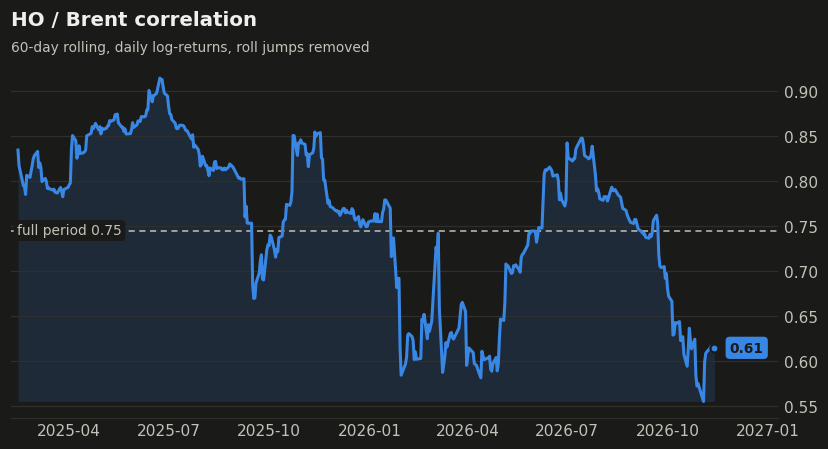

In [23]:
rho = params.rolling_rho
fig, ax = plt.subplots(figsize=(9, 4.2))
area_line(ax, rho.index, rho.values)
ax.margins(x=0.01)
ref_line(ax, params.rho, f"full period {params.rho:.2f}")
last_value(ax, rho.index[-1], rho.values[-1])
price_axis_right(ax)
titles(ax, "HO / Brent correlation", "60-day rolling, daily log-returns, roll jumps removed")
plt.show()

## 4. Price the APO

In [24]:
VOL_HO, VOL_BR = 0.30, 0.32   # implied vols: inputs, update from your options source

market = MarketData(
    today=date.today(),
    rate=0.04,
    quotes={"HO": Quote(f_ho, VOL_HO), "BRENT": Quote(f_br, VOL_BR)},
    correlations={("HO", "BRENT"): params.rho},
)

jc = joint_calendar(nymex_calendar(), ice_futures_europe_calendar())

sch = AveragingSchedule(
        pricing_period=f"{pricing_year}-{pricing_month:02d}",
        calendar=jc,
    )

apo = APO(
    legs=[Leg("HO", 1), Leg("BRENT", -1)],
    strike=round(f_ho - f_br),   # ATM
    quantity=25_000,
    schedule=sch
)
pricer = Pricer(model="kirk", market=market)

for model in ("bachelier", "kirk", "mc"):
    p = pricer.with_model(model)
    d_ho, d_br = p.deltas(apo).values()
    print(f"{model:<10} PV {p.pv(apo):6.3f} $/bbl | delta HO {d_ho:+.3f} | delta Brent {d_br:+.3f}")

bachelier  PV  8.940 $/bbl | delta HO +0.482 | delta Brent -0.482
kirk       PV  8.947 $/bbl | delta HO +0.512 | delta Brent -0.461
mc         PV  8.933 $/bbl | delta HO +0.511 | delta Brent -0.460


## 5. Assumed vs historical correlation

The static notebook assumes 0.95. How much does the estimate from history change the price?

In [25]:
for label, rho in (("assumed", 0.95), ("historical", params.rho)):
    m = market.model_copy(update={"correlations": {("HO", "BRENT"): rho}})
    print(f"rho {label:<10} {rho:.3f}: Kirk PV {pricer.with_market(m).pv(apo):.3f} $/bbl")

rho assumed    0.950: Kirk PV 6.192 $/bbl
rho historical 0.745: Kirk PV 8.947 $/bbl
